In [9]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import warnings


warnings.filterwarnings("ignore", message=".*inplace keyword.*")

t = yf.Ticker("FCNTX")
adj = t.history(start="2015-01-01", auto_adjust=True)["Close"]
raw = t.history(start="2015-01-01", auto_adjust=False)["Close"]

print(len(adj), adj.index.min().date(), adj.index.max().date())
adj.head()

2980 2015-01-02 2026-11-06


Date
2015-01-02 00:00:00-05:00    4.804189
2015-01-05 00:00:00-05:00    4.717243
2015-01-06 00:00:00-05:00    4.667630
2015-01-07 00:00:00-05:00    4.725595
2015-01-08 00:00:00-05:00    4.809594
Name: Close, dtype: float64

In [10]:
ret = adj.pct_change().dropna()
ret.describe()

count    2979.000000
mean        0.000642
std         0.012072
min        -0.118084
25%        -0.004429
50%         0.001036
75%         0.006752
max         0.097682
Name: Close, dtype: float64

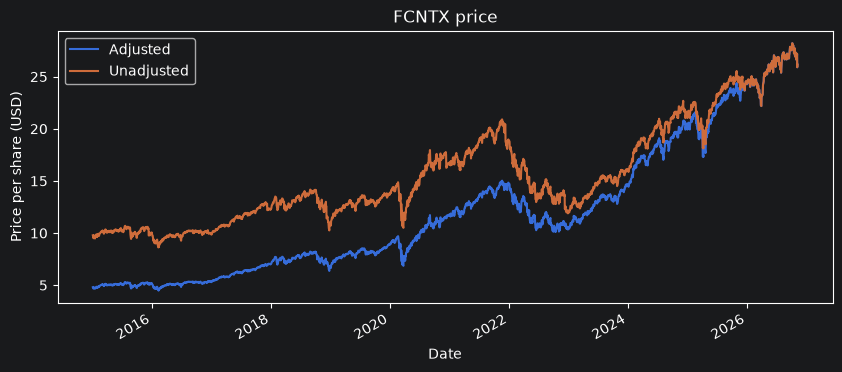

In [11]:
ax = adj.plot(label="Adjusted", figsize=(10, 4))
raw.plot(ax=ax, label="Unadjusted")
ax.legend()
ax.set_title("FCNTX price")
ax.set_xlabel("Date")
ax.set_ylabel("Price per share (USD)")
plt.show()

In [12]:
# Adjusted Price
first_adj = adj.iloc[0]
last_adj = adj.iloc[-1]
print(first_adj, last_adj)

# Raw Price
first_raw = raw.iloc[0]
last_raw = raw.iloc[-1]
print(first_raw, last_raw)

total_adj = (last_adj / first_adj) - 1
print(f"Adjusted total return: {total_adj:.1%}")

total_raw = (last_raw / first_raw) - 1
print(f"Raw total return: {total_raw:.1%}")

# Adjusted return shows what the investor actually +457% taking into account
# (Payables including Dividends and capital gain distributions)
# comparison to +174% of raw return which is just the displayed price change



4.804189205169678 26.149999618530273
9.779999732971191 26.149999618530273
Adjusted total return: 444.3%
Raw total return: 167.4%


In [13]:
daily_mean = ret.mean()
daily_std = ret.std()
print(daily_mean, daily_std)

# Total trading days is 252 days * daily return
annual_return = 252 * daily_mean
# Variance = vol squared
annual_vol = daily_std * (252 ** 0.5)
print(f"Total annual return: {annual_return:.1%}")
print(f"Annual Vol: {annual_vol:.1%}")

years = ((adj.index[-1] - adj.index[0]).days / 365.25)
print(1.164 ** years - 1)


0.0006420153981793797 0.012072486074187903
Total annual return: 16.2%
Annual Vol: 19.2%
5.041479509852385


In [14]:
CAGR = ((last_adj / first_adj) ** (1/years)) - 1
print(f"CAGR: {CAGR:.1%}")

CAGR: 15.4%


Date
2026-11-02 00:00:00-05:00    28.209999
2026-11-03 00:00:00-05:00    28.209999
2026-11-04 00:00:00-05:00    28.209999
2026-11-05 00:00:00-05:00    28.209999
2026-11-06 00:00:00-05:00    28.209999
Name: Close, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

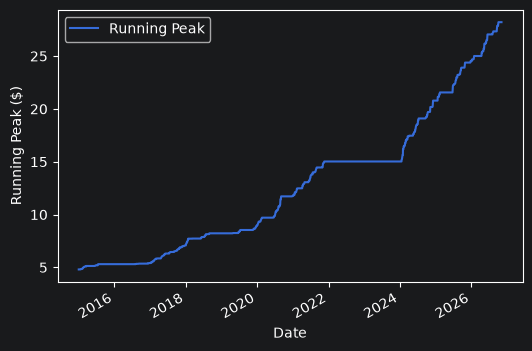

In [15]:
# Running Peak
peak = adj.cummax()
print(peak.tail())
ax = peak.plot(label="Running Peak", figsize=(6, 4))
ax.set_ylabel("Running Peak ($)")
ax.set_xlabel("Date")
ax.legend()
plt.show


Date
2026-11-02 00:00:00-05:00   -0.057781
2026-11-03 00:00:00-05:00   -0.050691
2026-11-04 00:00:00-05:00   -0.036157
2026-11-05 00:00:00-05:00   -0.081886
2026-11-06 00:00:00-05:00   -0.073024
Name: Close, dtype: float64
Current Drawdown: -7.3%
max drawdown: -32.6% on 2022-09-30


<function matplotlib.pyplot.show(close=None, block=None)>

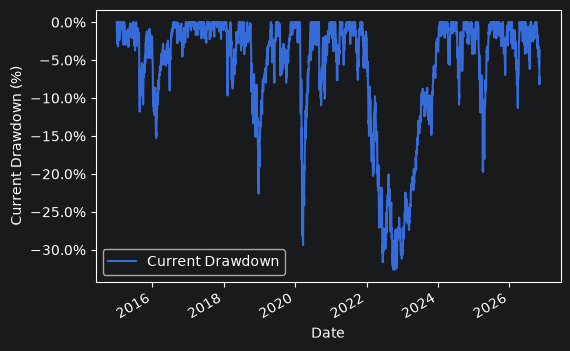

In [16]:
# Drawdown
drawdown = adj / peak - 1
worst_drawdown = drawdown.min()
worst_drawdown_date = drawdown.idxmin().date()
print(drawdown.tail())
print(f"Current Drawdown: {drawdown.iloc[-1]:.1%}")
print(f"max drawdown: {worst_drawdown:.1%} on {worst_drawdown_date}")

ax = drawdown.plot(label="Current Drawdown", figsize=(6, 4))

from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(1.0))


ax.set_ylabel("Current Drawdown (%)")
ax.set_xlabel("Date")
ax.legend()
plt.show


In [17]:
info = yf.Ticker("FCNTX").info
print(info.keys())

funds = pd.read_csv("../config/funds.csv")
funds.head()

names = []
fees = []


for t in funds["ticker"]:
    info = yf.Ticker(t).info
    names.append(info.get("longName"))
    fees.append(info.get("netExpenseRatio"))
    print(t)

print(names)
print(fees)

funds["name"] = names
funds["expense_ratio"] = pd.Series(fees) / 100
funds.to_csv("../config/funds.csv", index=False)


dict_keys(['address1', 'address2', 'address3', 'phone', 'longBusinessSummary', 'companyOfficers', 'executiveTeam', 'maxAge', 'priceHint', 'previousClose', 'regularMarketPreviousClose', 'averageVolume', 'averageVolume10days', 'averageDailyVolume10Day', 'yield', 'ytdReturn', 'totalAssets', 'fiftyTwoWeekLow', 'fiftyTwoWeekHigh', 'allTimeHigh', 'allTimeLow', 'fulldayPrice', 'fulldayChange', 'fulldayChangePercent', 'fiftyDayAverage', 'twoHundredDayAverage', 'currency', 'tradeable', 'morningStarOverallRating', 'morningStarRiskRating', 'annualReportExpenseRatio', 'beta3Year', 'fundInceptionDate', 'lastDividendValue', 'lastCapGain', 'annualHoldingsTurnover', 'quoteType', 'symbol', 'language', 'region', 'typeDisp', 'quoteSourceName', 'triggerable', 'customPriceAlertConfidence', 'corporateActions', 'regularMarketTime', 'exchange', 'messageBoardId', 'exchangeTimezoneName', 'exchangeTimezoneShortName', 'gmtOffSetMilliseconds', 'market', 'esgPopulated', 'marketState', 'dividendRate', 'dividendYield